**Name - Harshal Mekhe**<br>
**PRN - 202401040051**<br>
**Roll - 14**<br>
**PS - Sudoku**<br>

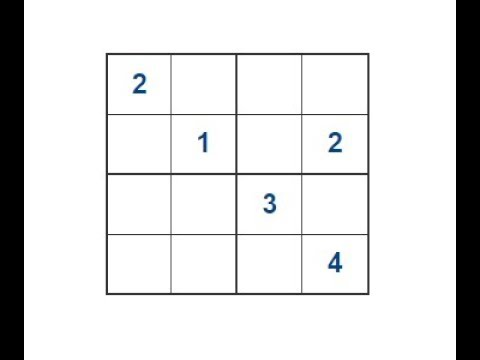

This assignment focuses on evaluating different problem-solving search strategies in Artificial Intelligence using the Sudoku problem.<br><br> A 4×4 Sudoku puzzle is selected as the common problem, and the solution is obtained using Uninformed Search techniques (BFS, DFS, DLS and IDDFS), Informed Search techniques (Best First Search and A*), Local/Optimization Search techniques (Hill Climbing and Genetic Algorithm), and Constraint Satisfaction Problem (CSP).<br><br> The performance of these approaches is compared based on factors such as execution time, number of states explored, search effort, and solution success, providing an understanding of how different AI search strategies perform when solving the same problem.

In [ ]:
import time
import random
import heapq
import math

from collections import deque

import pandas as pd
import matplotlib.pyplot as plt


# Sudoku size
N = 4

# Size of each sub-grid
BOX_SIZE = 2

In [ ]:
PUZZLE = (
    0, 0, 2, 0,
    0, 0, 0, 3,
    0, 1, 0, 0,
    4, 0, 0, 0
)

print("Initial Sudoku:")
print()

Initial Sudoku:



In [ ]:
def print_sudoku(state):

    for row in range(N):

        for col in range(N):

            value = state[row * N + col]

            if value == 0:
                print(".", end=" ")
            else:
                print(value, end=" ")

            if col == 1:
                print("|", end=" ")

        print()

        if row == 1:
            print("------+------")


print_sudoku(PUZZLE)

. . | 2 . 
. . | . 3 
------+------
. 1 | . . 
4 . | . . 


**Common Sudoku Functions**

In [ ]:


def is_valid_value(state, index, value):

    row = index // N
    col = index % N


    for c in range(N):

        if c != col:

            if state[row * N + c] == value:
                return False

    for r in range(N):

        if r != row:

            if state[r * N + col] == value:
                return False


    box_row = (row // BOX_SIZE) * BOX_SIZE
    box_col = (col // BOX_SIZE) * BOX_SIZE

    for r in range(box_row, box_row + BOX_SIZE):

        for c in range(box_col, box_col + BOX_SIZE):

            current_index = r * N + c

            if current_index != index:

                if state[current_index] == value:
                    return False

    return True




def get_next_empty_cell(state):

    for i in range(len(state)):

        if state[i] == 0:
            return i

    return None




def get_candidates(state, index):

    if state[index] != 0:
        return []

    candidates = []

    for value in range(1, N + 1):

        if is_valid_value(state, index, value):
            candidates.append(value)

    return candidates




def get_successors(state):

    index = get_next_empty_cell(state)

    if index is None:
        return []

    successors = []

    for value in get_candidates(state, index):

        new_state = list(state)

        new_state[index] = value

        successors.append(tuple(new_state))

    return successors




def is_solution(state):

    # No empty cells
    if 0 in state:
        return False

    # Check every cell
    for index in range(len(state)):

        if not is_valid_value(state, index, state[index]):
            return False

    return True

**Breadth First Search**

In [ ]:


def bfs():

    start_time = time.perf_counter()

    queue = deque([PUZZLE])

    states_explored = 0
    states_generated = 1
    max_memory = 1

    while queue:

        state = queue.popleft()

        states_explored += 1


        if is_solution(state):

            execution_time = time.perf_counter() - start_time

            return state, {
                "states_explored": states_explored,
                "states_generated": states_generated,
                "max_memory": max_memory,
                "time": execution_time
            }


        for child in get_successors(state):

            queue.append(child)

            states_generated += 1

        max_memory = max(max_memory, len(queue))

    return None, {}

**Depth First Search**

In [ ]:


def dfs():

    start_time = time.perf_counter()

    stack = [PUZZLE]

    states_explored = 0
    states_generated = 1
    max_memory = 1

    while stack:

        state = stack.pop()

        states_explored += 1


        if is_solution(state):

            execution_time = time.perf_counter() - start_time

            return state, {
                "states_explored": states_explored,
                "states_generated": states_generated,
                "max_memory": max_memory,
                "time": execution_time
            }

        children = get_successors(state)


        for child in reversed(children):

            stack.append(child)

            states_generated += 1

        max_memory = max(max_memory, len(stack))

    return None, {}

**Depth Limited Search**

In [ ]:


def dls(limit=10):

    start_time = time.perf_counter()

    states_explored = 0
    states_generated = 0
    max_depth = 0

    def recursive_search(state, depth):

        nonlocal states_explored
        nonlocal states_generated
        nonlocal max_depth

        states_explored += 1

        max_depth = max(max_depth, depth)


        if is_solution(state):
            return state


        if depth >= limit:
            return None


        for child in get_successors(state):

            states_generated += 1

            result = recursive_search(
                child,
                depth + 1
            )

            if result is not None:
                return result

        return None

    solution = recursive_search(
        PUZZLE,
        0
    )

    execution_time = time.perf_counter() - start_time

    return solution, {
        "states_explored": states_explored,
        "states_generated": states_generated,
        "max_memory": max_depth + 1,
        "time": execution_time
    }

**IDDFS - ITERATIVE DEEPENING DEPTH FIRST SEARCH**

In [ ]:


def iddfs():

    start_time = time.perf_counter()

    total_explored = 0
    total_generated = 0
    max_memory = 0


    max_limit = PUZZLE.count(0)

    for limit in range(max_limit + 1):

        solution, metrics = dls(limit)

        total_explored += metrics["states_explored"]

        total_generated += metrics["states_generated"]

        max_memory = max(
            max_memory,
            metrics["max_memory"]
        )


        if solution is not None:

            execution_time = time.perf_counter() - start_time

            return solution, {
                "states_explored": total_explored,
                "states_generated": total_generated,
                "max_memory": max_memory,
                "time": execution_time
            }

    return None, {}

**Bidirectional Search**

In [3]:




def bidirectional_search():

    start_time = time.perf_counter()


    start_state = PUZZLE


    goal_state = (
        1, 3, 2, 4,
        2, 4, 1, 3,
        3, 1, 4, 2,
        4, 2, 3, 1
    )


    fixed_cells = {
        i for i in range(len(PUZZLE))
        if PUZZLE[i] != 0
    }


    def forward_successors(state):

        successors = []

        for index in range(len(state)):

            if state[index] == 0:

                for value in get_candidates(state, index):

                    new_state = list(state)
                    new_state[index] = value

                    successors.append(tuple(new_state))

        return successors


    def backward_successors(state):

        successors = []

        for index in range(len(state)):


            if index not in fixed_cells and state[index] != 0:

                new_state = list(state)
                new_state[index] = 0

                successors.append(tuple(new_state))

        return successors



    forward_queue = deque([start_state])
    backward_queue = deque([goal_state])

    forward_visited = {
        start_state: None
    }

    backward_visited = {
        goal_state: None
    }

    states_explored = 0
    states_generated = 2
    max_memory = 2

    meeting_state = None



    while forward_queue and backward_queue:



        current = forward_queue.popleft()

        states_explored += 1


        if current in backward_visited:

            meeting_state = current
            break

        for child in forward_successors(current):

            if child not in forward_visited:

                forward_visited[child] = current
                forward_queue.append(child)
                states_generated += 1

                if child in backward_visited:

                    meeting_state = child
                    break

        if meeting_state is not None:
            break



        current = backward_queue.popleft()

        states_explored += 1


        if current in forward_visited:

            meeting_state = current
            break

        for child in backward_successors(current):

            if child not in backward_visited:

                backward_visited[child] = current
                backward_queue.append(child)
                states_generated += 1

                if child in forward_visited:

                    meeting_state = child
                    break

        if meeting_state is not None:
            break

        max_memory = max(
            max_memory,
            len(forward_queue) + len(backward_queue)
        )



    if meeting_state is None:

        execution_time = time.perf_counter() - start_time

        return None, {
            "states_explored": states_explored,
            "states_generated": states_generated,
            "max_memory": max_memory,
            "time": execution_time
        }



    forward_path = []

    state = meeting_state

    while state is not None:

        forward_path.append(state)
        state = forward_visited[state]

    forward_path.reverse()



    backward_path = []

    state = backward_visited[meeting_state]

    while state is not None:

        backward_path.append(state)
        state = backward_visited[state]



    full_path = (
        forward_path +
        backward_path
    )

    solution = full_path[-1]

    execution_time = time.perf_counter() - start_time

    return solution, {
        "states_explored": states_explored,
        "states_generated": states_generated,
        "max_memory": max_memory,
        "time": execution_time,
        "meeting_state": meeting_state,
        "path_length": len(full_path) - 1
    }

**BEST FIRST SEARCH**

In [ ]:


def best_first_search():

    start_time = time.perf_counter()

    counter = 0



    priority_queue = [
        (
            heuristic(PUZZLE),
            counter,
            PUZZLE
        )
    ]

    visited = set()

    states_explored = 0
    states_generated = 1
    max_memory = 1

    while priority_queue:

        h, _, state = heapq.heappop(
            priority_queue
        )

        if state in visited:
            continue

        visited.add(state)

        states_explored += 1


        if is_solution(state):

            execution_time = time.perf_counter() - start_time

            return state, {
                "states_explored": states_explored,
                "states_generated": states_generated,
                "max_memory": max_memory,
                "time": execution_time
            }


        for child in get_successors(state):

            if child not in visited:

                counter += 1

                heapq.heappush(
                    priority_queue,
                    (
                        heuristic(child),
                        counter,
                        child
                    )
                )

                states_generated += 1

        max_memory = max(
            max_memory,
            len(priority_queue)
        )

    return None, {}

**A Star SEARCH**

In [ ]:


def a_star():

    start_time = time.perf_counter()

    counter = 0


    initial_g = 0

    initial_h = heuristic(PUZZLE)

    priority_queue = [
        (
            initial_g + initial_h,
            initial_g,
            counter,
            PUZZLE
        )
    ]

    best_g = {
        PUZZLE: 0
    }

    states_explored = 0
    states_generated = 1
    max_memory = 1

    while priority_queue:

        f, g, _, state = heapq.heappop(
            priority_queue
        )


        if g != best_g.get(state):
            continue

        states_explored += 1


        if is_solution(state):

            execution_time = time.perf_counter() - start_time

            return state, {
                "states_explored": states_explored,
                "states_generated": states_generated,
                "max_memory": max_memory,
                "time": execution_time
            }


        for child in get_successors(state):

            new_g = g + 1

            if new_g < best_g.get(
                child,
                math.inf
            ):

                best_g[child] = new_g

                h = heuristic(child)

                f = new_g + h

                counter += 1

                heapq.heappush(
                    priority_queue,
                    (
                        f,
                        new_g,
                        counter,
                        child
                    )
                )

                states_generated += 1

        max_memory = max(
            max_memory,
            len(priority_queue)
        )

    return None, {}

**Functions For Local Search**

In [ ]:


def count_conflicts(board):

    conflicts = 0


    for row in range(N):

        values = [
            board[row * N + col]
            for col in range(N)
        ]

        conflicts += (
            len(values) -
            len(set(values))
        )


    for col in range(N):

        values = [
            board[row * N + col]
            for row in range(N)
        ]

        conflicts += (
            len(values) -
            len(set(values))
        )


    for box_row in range(0, N, BOX_SIZE):

        for box_col in range(0, N, BOX_SIZE):

            values = []

            for row in range(
                box_row,
                box_row + BOX_SIZE
            ):

                for col in range(
                    box_col,
                    box_col + BOX_SIZE
                ):

                    values.append(
                        board[row * N + col]
                    )

            conflicts += (
                len(values) -
                len(set(values))
            )

    return conflicts




def random_complete_board(rng):

    board = list(PUZZLE)

    for row in range(N):

        row_start = row * N

        fixed_values = {
            board[row_start + col]
            for col in range(N)
            if board[row_start + col] != 0
        }

        missing_values = [
            value
            for value in range(1, N + 1)
            if value not in fixed_values
        ]

        rng.shuffle(missing_values)

        index = 0

        for col in range(N):

            position = row_start + col

            if board[position] == 0:

                board[position] = (
                    missing_values[index]
                )

                index += 1

    return board

**Hill Climbing**

In [ ]:


def hill_climbing(
    seed=42,
    max_restarts=100,
    max_iterations=1000
):

    rng = random.Random(seed)

    start_time = time.perf_counter()

    total_iterations = 0
    total_evaluations = 0
    restarts = 0

    best_overall = None
    best_conflicts = float("inf")

    for restart in range(max_restarts):

        restarts += 1

        current = random_complete_board(rng)

        current_conflicts = count_conflicts(
            current
        )

        total_evaluations += 1

        for iteration in range(max_iterations):

            total_iterations += 1


            if current_conflicts == 0:

                execution_time = (
                    time.perf_counter()
                    - start_time
                )

                return tuple(current), {
                    "iterations": total_iterations,
                    "evaluations": total_evaluations,
                    "restarts": restarts,
                    "final_conflicts": 0,
                    "time": execution_time
                }

            best_neighbor = None

            best_neighbor_conflicts = (
                current_conflicts
            )


            for row in range(N):

                mutable_cells = [
                    row * N + col
                    for col in range(N)
                    if PUZZLE[row * N + col] == 0
                ]

                for i in range(
                    len(mutable_cells)
                ):

                    for j in range(
                        i + 1,
                        len(mutable_cells)
                    ):

                        neighbor = current.copy()

                        pos1 = mutable_cells[i]
                        pos2 = mutable_cells[j]

                        neighbor[pos1], neighbor[pos2] = (
                            neighbor[pos2],
                            neighbor[pos1]
                        )

                        conflicts = count_conflicts(
                            neighbor
                        )

                        total_evaluations += 1

                        if (
                            conflicts
                            < best_neighbor_conflicts
                        ):

                            best_neighbor_conflicts = (
                                conflicts
                            )

                            best_neighbor = neighbor


            if (
                current_conflicts
                < best_conflicts
            ):

                best_conflicts = current_conflicts

                best_overall = current.copy()


            if best_neighbor is None:
                break

            current = best_neighbor

            current_conflicts = (
                best_neighbor_conflicts
            )

    execution_time = (
        time.perf_counter() -
        start_time
    )

    return tuple(best_overall), {
        "iterations": total_iterations,
        "evaluations": total_evaluations,
        "restarts": restarts,
        "final_conflicts": best_conflicts,
        "time": execution_time
    }

**Genetic Algorithm**

In [ ]:


def genetic_algorithm(
    seed=42,
    population_size=50,
    max_generations=1000,
    mutation_rate=0.20,
    elite_size=2
):

    rng = random.Random(seed)

    start_time = time.perf_counter()



    def create_chromosome():

        return random_complete_board(rng)



    def fitness(chromosome):

        return -count_conflicts(
            chromosome
        )


    population = [
        create_chromosome()
        for _ in range(population_size)
    ]

    evaluations = 0

    best_solution = None



    for generation in range(
        max_generations
    ):

        fitness_values = []

        for chromosome in population:

            fitness_values.append(
                fitness(chromosome)
            )

        evaluations += len(population)


        best_index = max(
            range(population_size),
            key=lambda i: fitness_values[i]
        )

        best_solution = (
            population[best_index].copy()
        )


        if count_conflicts(
            best_solution
        ) == 0:

            execution_time = (
                time.perf_counter()
                - start_time
            )

            return tuple(best_solution), {
                "generations": generation + 1,
                "evaluations": evaluations,
                "final_conflicts": 0,
                "time": execution_time
            }



        sorted_population = sorted(
            population,
            key=fitness,
            reverse=True
        )

        new_population = [
            chromosome.copy()
            for chromosome
            in sorted_population[:elite_size]
        ]



        def tournament_selection():

            contestants = rng.sample(
                population,
                3
            )

            return max(
                contestants,
                key=fitness
            )



        while len(new_population) < population_size:

            parent1 = tournament_selection()

            parent2 = tournament_selection()



            child = []

            for row in range(N):

                if rng.random() < 0.5:

                    source = parent1

                else:

                    source = parent2

                row_values = source[
                    row * N:
                    (row + 1) * N
                ]

                child.extend(row_values)



            if rng.random() < mutation_rate:

                row = rng.randrange(N)

                mutable_cells = [
                    row * N + col
                    for col in range(N)
                    if PUZZLE[row * N + col] == 0
                ]

                if len(mutable_cells) >= 2:

                    pos1, pos2 = rng.sample(
                        mutable_cells,
                        2
                    )

                    child[pos1], child[pos2] = (
                        child[pos2],
                        child[pos1]
                    )

            new_population.append(child)

        population = new_population

    execution_time = (
        time.perf_counter()
        - start_time
    )

    final_conflicts = count_conflicts(
        best_solution
    )

    return tuple(best_solution), {
        "generations": max_generations,
        "evaluations": evaluations,
        "final_conflicts": final_conflicts,
        "time": execution_time
    }

**CSP - CONSTRAINT SATISFACTION PROBLEM**

In [ ]:


def solve_csp():

    start_time = time.perf_counter()

    board = list(PUZZLE)

    nodes = 0
    backtracks = 0
    constraint_checks = 0



    def possible_values(index):

        nonlocal constraint_checks

        values = []

        for value in range(1, N + 1):

            constraint_checks += 1

            if is_valid_value(
                tuple(board),
                index,
                value
            ):

                values.append(value)

        return values



    def select_variable():

        best_cell = None
        best_domain = None

        for index in range(len(board)):

            if board[index] == 0:

                domain = possible_values(
                    index
                )


                if len(domain) == 0:
                    return index, []

                if (
                    best_domain is None
                    or len(domain)
                    < len(best_domain)
                ):

                    best_cell = index

                    best_domain = domain

        return best_cell, best_domain



    def backtrack():

        nonlocal nodes
        nonlocal backtracks


        if 0 not in board:

            return tuple(board)

        cell, domain = select_variable()


        if not domain:

            backtracks += 1

            return None

        for value in domain:

            nodes += 1

            board[cell] = value

            result = backtrack()

            if result is not None:

                return result


            board[cell] = 0

        backtracks += 1

        return None

    solution = backtrack()

    execution_time = (
        time.perf_counter()
        - start_time
    )

    return solution, {
        "nodes": nodes,
        "backtracks": backtracks,
        "constraint_checks": constraint_checks,
        "time": execution_time
    }

**Run BFS**

In [ ]:


bfs_solution, bfs_metrics = bfs()

print("BFS Solution:")
print_sudoku(bfs_solution)

print("\nMetrics:")
print(bfs_metrics)

BFS Solution:
1 3 | 2 4 
2 4 | 1 3 
------+------
3 1 | 4 2 
4 2 | 3 1 

Metrics:
{'states_explored': 26, 'states_generated': 27, 'max_memory': 3, 'time': 0.00018138500001896318}


**Run DFS**

In [ ]:


dfs_solution, dfs_metrics = dfs()

print("DFS Solution:")
print_sudoku(dfs_solution)

print("\nMetrics:")
print(dfs_metrics)

DFS Solution:
1 3 | 2 4 
2 4 | 1 3 
------+------
3 1 | 4 2 
4 2 | 3 1 

Metrics:
{'states_explored': 13, 'states_generated': 15, 'max_memory': 3, 'time': 0.00013322300003437704}


**Run DLS**

In [ ]:


dls_solution, dls_metrics = dls(
    limit=PUZZLE.count(0)
)

print("DLS Solution:")
print_sudoku(dls_solution)

print("\nMetrics:")
print(dls_metrics)

DLS Solution:
1 3 | 2 4 
2 4 | 1 3 
------+------
3 1 | 4 2 
4 2 | 3 1 

Metrics:
{'states_explored': 13, 'states_generated': 12, 'max_memory': 13, 'time': 0.00014821400009168428}


**Run IDDFS**

In [ ]:

iddfs_solution, iddfs_metrics = iddfs()

print("IDDFS Solution:")
print_sudoku(iddfs_solution)

print("\nMetrics:")
print(iddfs_metrics)

IDDFS Solution:
1 3 | 2 4 
2 4 | 1 3 
------+------
3 1 | 4 2 
4 2 | 3 1 

Metrics:
{'states_explored': 175, 'states_generated': 162, 'max_memory': 13, 'time': 0.0008287639999480234}


**Run Best First Search**

In [ ]:


best_solution, best_metrics = best_first_search()

print("Best First Search Solution:")
print_sudoku(best_solution)

print("\nMetrics:")
print(best_metrics)

Best First Search Solution:
1 3 | 2 4 
2 4 | 1 3 
------+------
3 1 | 4 2 
4 2 | 3 1 

Metrics:
{'states_explored': 13, 'states_generated': 15, 'max_memory': 3, 'time': 0.0007630789999666376}


**Run A Star**

In [ ]:


astar_solution, astar_metrics = a_star()

print("A* Solution:")
print_sudoku(astar_solution)

print("\nMetrics:")
print(astar_metrics)

A* Solution:
1 3 | 2 4 
2 4 | 1 3 
------+------
3 1 | 4 2 
4 2 | 3 1 

Metrics:
{'states_explored': 13, 'states_generated': 15, 'max_memory': 3, 'time': 0.0005546990000766527}


**Run Hill Climbing**

In [ ]:


hill_solution, hill_metrics = hill_climbing()

print("Hill Climbing Solution:")
print_sudoku(hill_solution)

print("\nMetrics:")
print(hill_metrics)

Hill Climbing Solution:
1 3 | 2 4 
2 4 | 1 3 
------+------
3 1 | 4 2 
4 2 | 3 1 

Metrics:
{'iterations': 3, 'evaluations': 25, 'restarts': 1, 'final_conflicts': 0, 'time': 0.00029743300001427997}


**Run Genetic Algorithm**

In [ ]:


ga_solution, ga_metrics = genetic_algorithm()

print("Genetic Algorithm Solution:")
print_sudoku(ga_solution)

print("\nMetrics:")
print(ga_metrics)

Genetic Algorithm Solution:
1 3 | 2 4 
2 4 | 1 3 
------+------
3 1 | 4 2 
4 2 | 3 1 

Metrics:
{'generations': 3, 'evaluations': 150, 'final_conflicts': 0, 'time': 0.009904153000093174}


**Run CSP**

In [ ]:


csp_solution, csp_metrics = solve_csp()

print("CSP Solution:")
print_sudoku(csp_solution)

print("\nMetrics:")
print(csp_metrics)

CSP Solution:
1 3 | 2 4 
2 4 | 1 3 
------+------
3 1 | 4 2 
4 2 | 3 1 

Metrics:
{'nodes': 12, 'backtracks': 0, 'constraint_checks': 312, 'time': 0.000425311999947553}


**Verify All Solutions**

In [ ]:


solutions = {
    "BFS": bfs_solution,
    "DFS": dfs_solution,
    "DLS": dls_solution,
    "IDDFS": iddfs_solution,
    "Best First": best_solution,
    "A*": astar_solution,
    "Hill Climbing": hill_solution,
    "Genetic Algorithm": ga_solution,
    "CSP": csp_solution
}

for algorithm, solution in solutions.items():

    if solution is not None and is_solution(solution):

        print(
            algorithm,
            "-> VALID SOLUTION"
        )

    else:

        print(
            algorithm,
            "-> NO VALID SOLUTION"
        )

BFS -> VALID SOLUTION
DFS -> VALID SOLUTION
DLS -> VALID SOLUTION
IDDFS -> VALID SOLUTION
Best First -> VALID SOLUTION
A* -> VALID SOLUTION
Hill Climbing -> VALID SOLUTION
Genetic Algorithm -> VALID SOLUTION
CSP -> VALID SOLUTION


**Performance Comparison**

In [ ]:


results = []

# ------------------------------------------------------------
# BFS
# ------------------------------------------------------------

results.append({
    "Algorithm": "BFS",
    "Category": "Uninformed",
    "Solution Found": is_solution(bfs_solution),
    "States Explored": bfs_metrics["states_explored"],
    "States Generated": bfs_metrics["states_generated"],
    "Memory / Frontier": bfs_metrics["max_memory"],
    "Time (sec)": bfs_metrics["time"]
})


# ------------------------------------------------------------
# DFS
# ------------------------------------------------------------

results.append({
    "Algorithm": "DFS",
    "Category": "Uninformed",
    "Solution Found": is_solution(dfs_solution),
    "States Explored": dfs_metrics["states_explored"],
    "States Generated": dfs_metrics["states_generated"],
    "Memory / Frontier": dfs_metrics["max_memory"],
    "Time (sec)": dfs_metrics["time"]
})


# ------------------------------------------------------------
# DLS
# ------------------------------------------------------------

results.append({
    "Algorithm": "DLS",
    "Category": "Uninformed",
    "Solution Found": is_solution(dls_solution),
    "States Explored": dls_metrics["states_explored"],
    "States Generated": dls_metrics["states_generated"],
    "Memory / Frontier": dls_metrics["max_memory"],
    "Time (sec)": dls_metrics["time"]
})


# ------------------------------------------------------------
# IDDFS
# ------------------------------------------------------------

results.append({
    "Algorithm": "IDDFS",
    "Category": "Uninformed",
    "Solution Found": is_solution(iddfs_solution),
    "States Explored": iddfs_metrics["states_explored"],
    "States Generated": iddfs_metrics["states_generated"],
    "Memory / Frontier": iddfs_metrics["max_memory"],
    "Time (sec)": iddfs_metrics["time"]
})


# ------------------------------------------------------------
# Best First
# ------------------------------------------------------------

results.append({
    "Algorithm": "Best First",
    "Category": "Informed",
    "Solution Found": is_solution(best_solution),
    "States Explored": best_metrics["states_explored"],
    "States Generated": best_metrics["states_generated"],
    "Memory / Frontier": best_metrics["max_memory"],
    "Time (sec)": best_metrics["time"]
})


# ------------------------------------------------------------
# A*
# ------------------------------------------------------------

results.append({
    "Algorithm": "A*",
    "Category": "Informed",
    "Solution Found": is_solution(astar_solution),
    "States Explored": astar_metrics["states_explored"],
    "States Generated": astar_metrics["states_generated"],
    "Memory / Frontier": astar_metrics["max_memory"],
    "Time (sec)": astar_metrics["time"]
})


# ------------------------------------------------------------
# Hill Climbing
# ------------------------------------------------------------

results.append({
    "Algorithm": "Hill Climbing",
    "Category": "Local Search",
    "Solution Found": is_solution(hill_solution),
    "States Explored": hill_metrics["evaluations"],
    "States Generated": hill_metrics["evaluations"],
    "Memory / Frontier": "-",
    "Time (sec)": hill_metrics["time"]
})


# ------------------------------------------------------------
# Genetic Algorithm
# ------------------------------------------------------------

results.append({
    "Algorithm": "Genetic Algorithm",
    "Category": "Local Search",
    "Solution Found": is_solution(ga_solution),
    "States Explored": ga_metrics["evaluations"],
    "States Generated": ga_metrics["evaluations"],
    "Memory / Frontier": "-",
    "Time (sec)": ga_metrics["time"]
})


# ------------------------------------------------------------
# CSP
# ------------------------------------------------------------

results.append({
    "Algorithm": "CSP",
    "Category": "Constraint Satisfaction",
    "Solution Found": is_solution(csp_solution),
    "States Explored": csp_metrics["nodes"],
    "States Generated": "-",
    "Memory / Frontier": "-",
    "Time (sec)": csp_metrics["time"]
})



df = pd.DataFrame(results)

df

,Algorithm,Category,Solution Found,States Explored,States Generated,Memory / Frontier,Time (sec)
0,BFS,Uninformed,True,26,27,3,0.000181
1,DFS,Uninformed,True,13,15,3,0.000133
2,DLS,Uninformed,True,13,12,13,0.000148
3,IDDFS,Uninformed,True,175,162,13,0.000829
4,Best First,Informed,True,13,15,3,0.000763
5,A*,Informed,True,13,15,3,0.000555
6,Hill Climbing,Local Search,True,25,25,-,0.000297
7,Genetic Algorithm,Local Search,True,150,150,-,0.009904
8,CSP,Constraint Satisfaction,True,12,-,-,0.000425


**Execution Time Graph**

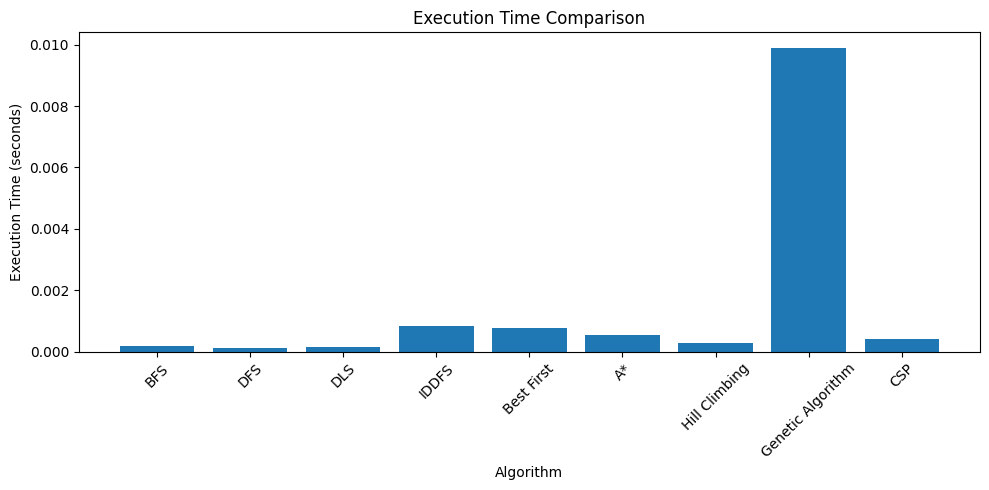

In [ ]:


plt.figure(figsize=(10, 5))

plt.bar(
    df["Algorithm"],
    df["Time (sec)"]
)

plt.xlabel("Algorithm")
plt.ylabel("Execution Time (seconds)")
plt.title("Execution Time Comparison")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

**States Explored Graph**

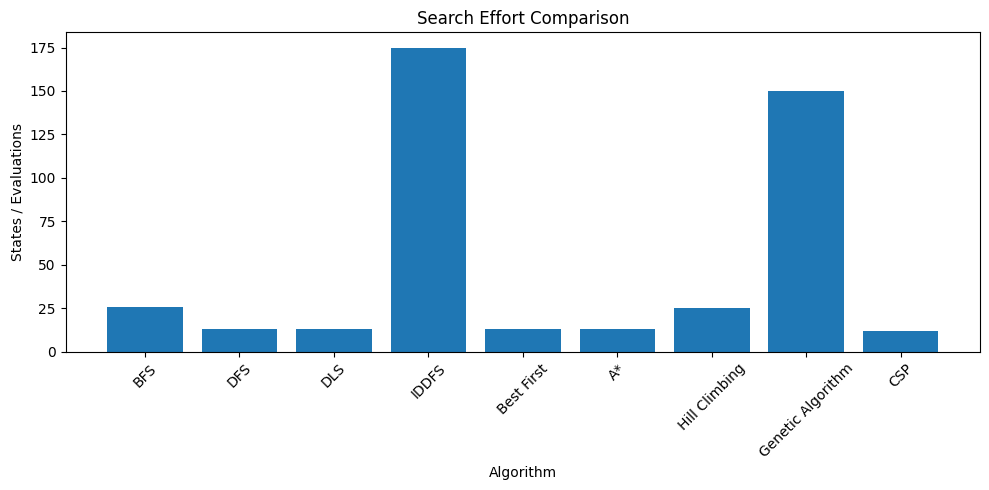

In [ ]:


numeric_states = pd.to_numeric(
    df["States Explored"],
    errors="coerce"
)

plt.figure(figsize=(10, 5))

plt.bar(
    df["Algorithm"],
    numeric_states
)

plt.xlabel("Algorithm")
plt.ylabel("States / Evaluations")
plt.title("Search Effort Comparison")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

**Category Wise Results**

In [ ]:


category_summary = (
    df.groupby("Category")["Time (sec)"]
    .mean()
    .reset_index()
)

print("Average Execution Time by Category:")
print(category_summary)

Average Execution Time by Category:
                  Category  Time (sec)
0  Constraint Satisfaction    0.000425
1                 Informed    0.000659
2             Local Search    0.005101
3               Uninformed    0.000323


**Display All Solutions**

In [ ]:


for algorithm, solution in solutions.items():

    print("=" * 45)

    print(algorithm)

    print("=" * 45)

    if solution is not None:

        print_sudoku(solution)

    else:

        print("No solution found")

    print()

BFS
1 3 | 2 4 
2 4 | 1 3 
------+------
3 1 | 4 2 
4 2 | 3 1 

DFS
1 3 | 2 4 
2 4 | 1 3 
------+------
3 1 | 4 2 
4 2 | 3 1 

DLS
1 3 | 2 4 
2 4 | 1 3 
------+------
3 1 | 4 2 
4 2 | 3 1 

IDDFS
1 3 | 2 4 
2 4 | 1 3 
------+------
3 1 | 4 2 
4 2 | 3 1 

Best First
1 3 | 2 4 
2 4 | 1 3 
------+------
3 1 | 4 2 
4 2 | 3 1 

A*
1 3 | 2 4 
2 4 | 1 3 
------+------
3 1 | 4 2 
4 2 | 3 1 

Hill Climbing
1 3 | 2 4 
2 4 | 1 3 
------+------
3 1 | 4 2 
4 2 | 3 1 

Genetic Algorithm
1 3 | 2 4 
2 4 | 1 3 
------+------
3 1 | 4 2 
4 2 | 3 1 

CSP
1 3 | 2 4 
2 4 | 1 3 
------+------
3 1 | 4 2 
4 2 | 3 1 

